In [1]:
from datetime import datetime

import geopandas as gp
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from shapely.geometry import Point

In [19]:
world = gp.read_file('/Users/go202/Downloads/ne_10m_admin_0_countries.zip')

In [2]:
tiles = gp.read_file('/Users/go202/Downloads/2024-10-01_performance_fixed_tiles.zip')

In [3]:
tiles.head()

,quadkey,avg_d_kbps,avg_u_kbps,avg_lat_ms,tests,devices,geometry
0,0022133222312323,33682,3278,99,1,1,"POLYGON ((-160.02136 70.64359, -160.01587 70.6..."
1,0022133222330031,97271,14686,192,2,2,"POLYGON ((-160.03235 70.63813, -160.02686 70.6..."
2,0022133222330033,92047,27325,101,1,1,"POLYGON ((-160.03235 70.63631, -160.02686 70.6..."
3,0022232311221201,537,255,1001,1,1,"POLYGON ((-171.86462 66.95588, -171.85913 66.9..."
4,0022302331120033,104525,4896,100,1,1,"POLYGON ((-166.09680 68.87342, -166.09131 68.8..."


In [6]:
len(tiles)

6561086

In [4]:
GDL_shapefiles = gp.read_file('/Users/go202/Downloads/GDL Shapefiles V6.3.zip')


In [5]:
GDL_shapefiles.head()

,gdlcode,continent,iso_code,geometry
0,AFGr101,Asia/Pacific,AFG,"POLYGON ((68.76606 33.66236, 68.75683 33.67773..."
1,AFGr102,Asia/Pacific,AFG,"POLYGON ((66.96691 33.59922, 66.95274 33.58840..."
2,AFGr103,Asia/Pacific,AFG,"POLYGON ((70.50643 33.92921, 70.50545 33.92891..."
3,AFGr104,Asia/Pacific,AFG,"POLYGON ((66.51614 35.14923, 66.51739 35.13391..."
4,AFGr105,Asia/Pacific,AFG,"POLYGON ((68.02675 35.08241, 67.99849 35.08043..."


In [8]:
!pip install dask-geopandas

  Using cached geopandas-1.0.1-py3-none-any.whl.metadata (2.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 kB 1.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.0 MB/s eta 0:00:0000:0100:01
Using cached geopandas-1.0.1-py3-none-any.whl (323 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 10.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: geopandas
    Found existing installation: geopandas 0.14.2
    Uninstalling geopandas-0.14.2:
      Successfully uninstalled geopandas-0.14.2


In [ ]:
from dask.diagnostics import ProgressBar

In [12]:
# Convert the GeoDataFrames to Dask GeoDataFrames
tiles_dask = dg.from_geopandas(tiles, npartitions=10)  # Adjust npartitions based on your system
GDL_shapefiles_dask = dg.from_geopandas(GDL_shapefiles, npartitions=10)

# Print an initial message
print("Starting the spatial join operation...")

# Perform the spatial join with 'intersects' as the predicate
global_tiles_dask = tiles_dask.sjoin(GDL_shapefiles_dask, how="inner", predicate='intersects')

# Print a message to indicate the task is moving
print("Spatial join completed. Converting result to Pandas GeoDataFrame...")

with ProgressBar():
    global_tiles = global_tiles_dask.compute()
# Convert the result back to a Pandas GeoDataFrame
global_tiles = global_tiles_dask.compute()

# Print a final message to confirm completion
print("Spatial join operation complete. Data is now available.")

Starting the spatial join operation...
Spatial join completed. Converting result to Pandas GeoDataFrame...
[########################################] | 100% Completed | 16m 49s


KeyboardInterrupt: 

In [14]:
g = global_tiles[['quadkey',	'avg_d_kbps',	'avg_u_kbps',	'avg_lat_ms',	'tests',	'devices',	'index_right', 'gdlcode', 'continent', 'iso_code']]

In [16]:
g.to_csv('very_important_subnational_speed.csv') 

<Axes: >

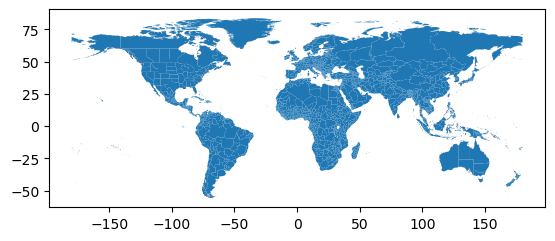

In [11]:
GDL_shapefiles.plot()

In [12]:
global_tiles = gp.sjoin(tiles, GDL_shapefiles, how="inner", op='intersects')

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3517: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):
